# Tugas 1 - Klasifikasi Wine Quality dengan KNN
  
| Nama              | NRP        |
|-------------------|------------|
| Ahmad Zaki Fauzan Nabil | 5054251044 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Wine Quality Dataset. Dataset bisa diakses melalui link berikut:\
🔗 https://www.kaggle.com/datasets/yasserh/wine-quality-dataset

Tujuan utama dari tugas ini adalah membangun model K-Nearest Neighbors (KNN) untuk mengklasifikasikan kualitas wine. 

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset & Eksplorasi Awal

- Memuat dataset, melihat struktur data, dan distribusi label.

2. Preprocessing 
- Memproses data agar siap untuk digunakan dalam membangun model.

3. Eksperimen Model KNN
- Bangun model KNN dengan mencoba beberapa nilai k (misalnya 3, 5, dan 7 --> BEBAS) serta dua metric jarak (seperti Euclidean dan Manhattan).
- Eksperimen ini bertujuan untuk membandingkan performa KNN dengan parameter yang berbeda.

4. Evaluasi Model
- Hitung metrik evaluasi seperti Accuracy, Precision, Recall, F1-Score, serta visualisasikan Confusion Matrix.

5. Analisis & Kesimpulan
- Bandingkan hasil antar eksperimen yang telah dilakukan dan berikan kesimpulan.


# 1. Persiapan Dataset & Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, dll) 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

# Pengaturan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)


In [2]:
#  Load Dataset dan menampilkan informasi dasar tentang dataset, seperti jumlah baris dan kolom, tipe data, jumlah nilai yang hilang, dan informasi lainnya yang dibutuhkan.

'''

data = pd.read_csv('namafile.csv')
data.head()
data.info()
data.describe()

! Cari fungsi-fungsi yang dapat digunakan untuk menampilkan informasi yang diinginkan. 

'''

# Load dataset Wine Quality
data = pd.read_csv('WineQT.csv')

# Menampilkan 5 baris pertama data
print("--- 5 Baris Pertama Dataset ---")
display(data.head())

# Menampilkan jumlah baris dan kolom
print(f"Dimensi dataset: {data.shape[0]} baris x {data.shape[1]} kolom\n")

# Menampilkan informasi struktur dan tipe data
print("--- Informasi Tipe Data & Kelengkapan Kolom ---")
data.info()

# Pengecekan missing values
print("\n--- Jumlah Missing Values per Kolom ---")
print(data.isnull().sum())

# Statistik deskriptif
print("\n--- Ringkasan Statistik Deskriptif ---")
display(data.describe().round(2))


--- 5 Baris Pertama Dataset ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


Dimensi dataset: 1143 baris x 13 kolom

--- Informasi Tipe Data & Kelengkapan Kolom ---
<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 K

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00,1143.00
mean,8.31,0.53,0.27,2.53,0.09,15.62,45.91,1.00,3.31,0.66,10.44,5.66,804.97
std,1.75,0.18,0.20,1.36,0.05,10.25,32.78,0.00,0.16,0.17,1.08,0.81,464.00
min,4.60,0.12,0.00,0.90,0.01,1.00,6.00,0.99,2.74,0.33,8.40,3.00,0.00
25%,7.10,0.39,0.09,1.90,0.07,7.00,21.00,1.00,3.20,0.55,9.50,5.00,411.00
50%,7.90,0.52,0.25,2.20,0.08,13.00,37.00,1.00,3.31,0.62,10.20,6.00,794.00
75%,9.10,0.64,0.42,2.60,0.09,21.00,61.00,1.00,3.40,0.73,11.10,6.00,1209.50
max,15.90,1.58,1.00,15.50,0.61,68.00,289.00,1.00,4.01,2.00,14.90,8.00,1597.00


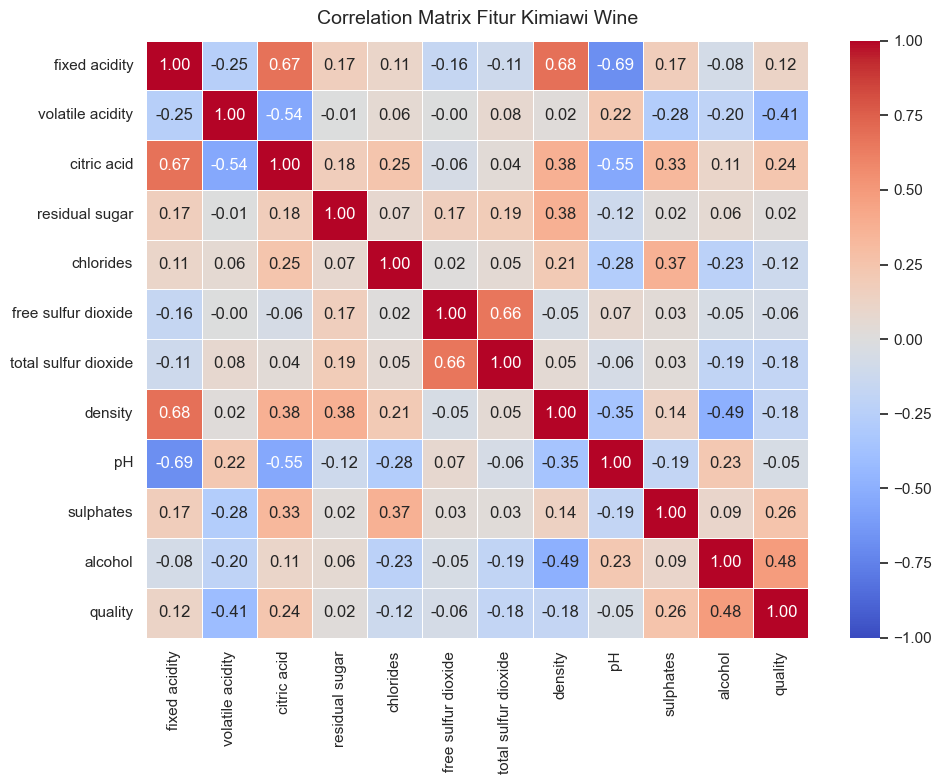

Tingkat korelasi fitur terhadap kualitas wine (quality):
quality                 1.000000
alcohol                 0.484866
sulphates               0.257710
citric acid             0.240821
fixed acidity           0.121970
residual sugar          0.022002
pH                     -0.052453
free sulfur dioxide    -0.063260
chlorides              -0.124085
density                -0.175208
total sulfur dioxide   -0.183339
volatile acidity       -0.407394
Name: quality, dtype: float64


In [3]:
# Tampilkan Korelasi Matrix

# Drop kolom 'Id' karena hanya indeks penanda, bukan karakteristik fisik/kimia wine
corr_matrix = data.drop(columns=['Id']).corr()

# Visualisasi heatmap korelasi
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix Fitur Kimiawi Wine', fontsize=14, pad=12)
plt.tight_layout()
plt.show()

# Menampilkan korelasi masing-masing fitur terhadap target 'quality' terurut
print("Tingkat korelasi fitur terhadap kualitas wine (quality):")
print(corr_matrix['quality'].sort_values(ascending=False))


Jumlah sampel tiap kelas quality:
quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64


C:\Users\ahmad\AppData\Local\Temp\ipykernel_16876\629162787.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='quality', data=data, palette='mako')


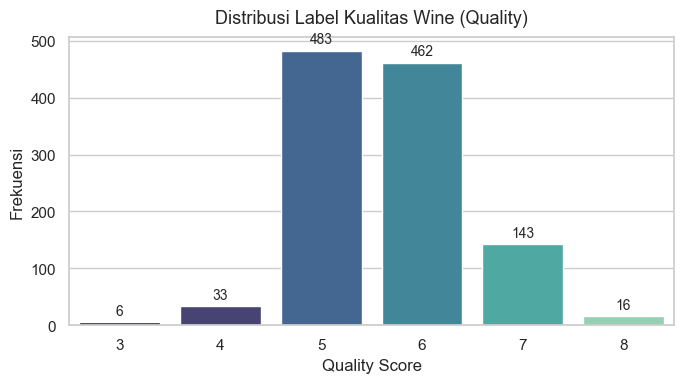

In [4]:
# Tampilkan distribusi label (quality) dalam bentuk visualisasi, misalnya menggunakan histogram atau bar plot.

# Menampilkan tabel jumlah per kelas
print("Jumlah sampel tiap kelas quality:")
print(data['quality'].value_counts().sort_index())

# Visualisasi countplot untuk melihat sebaran kelas
plt.figure(figsize=(7, 4))
ax = sns.countplot(x='quality', data=data, palette='mako')
plt.title('Distribusi Label Kualitas Wine (Quality)', fontsize=13, pad=10)
plt.xlabel('Quality Score')
plt.ylabel('Frekuensi')

# Menambahkan angka di atas setiap bar plot
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3), 
                textcoords='offset points')

plt.tight_layout()
plt.show()


## Silahkan Lakukan Exploratory Data Analysis (EDA) tambahan yang dibutuhkan. 

C:\Users\ahmad\AppData\Local\Temp\ipykernel_16876\4049835838.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y='alcohol', data=data, ax=axes[0], palette='Blues')


C:\Users\ahmad\AppData\Local\Temp\ipykernel_16876\4049835838.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y='volatile acidity', data=data, ax=axes[1], palette='Reds')


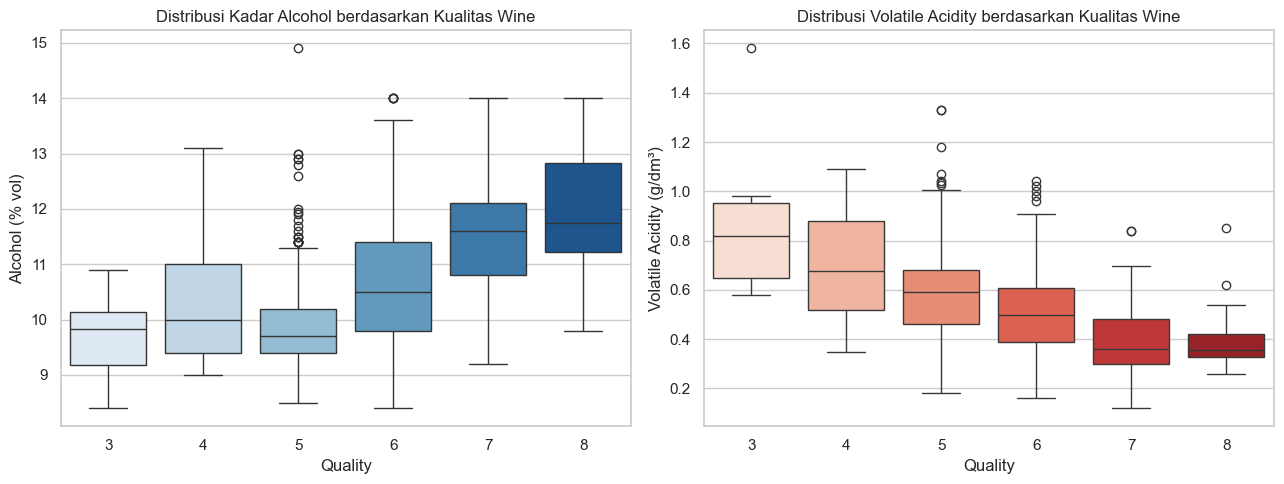

In [5]:
# EDA Tambahan: Hubungan antara dua fitur dengan korelasi tertinggi (alcohol & volatile acidity) terhadap kualitas wine

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Boxplot hubungan alcohol terhadap quality
sns.boxplot(x='quality', y='alcohol', data=data, ax=axes[0], palette='Blues')
axes[0].set_title('Distribusi Kadar Alcohol berdasarkan Kualitas Wine', fontsize=12)
axes[0].set_xlabel('Quality')
axes[0].set_ylabel('Alcohol (% vol)')

# Boxplot hubungan volatile acidity terhadap quality
sns.boxplot(x='quality', y='volatile acidity', data=data, ax=axes[1], palette='Reds')
axes[1].set_title('Distribusi Volatile Acidity berdasarkan Kualitas Wine', fontsize=12)
axes[1].set_xlabel('Quality')
axes[1].set_ylabel('Volatile Acidity (g/dm³)')

plt.tight_layout()
plt.show()


# 2. Preprocessing




In [6]:
# NaN handling (drop, impute, etc.), duplicate handling, dan lain-lain.

# Membuat salinan dataframe untuk preprocessing
df = data.copy()

# 1. Hapus kolom 'Id' karena hanya identifikasi sampel, bukan karakteristik kimiawi wine
if 'Id' in df.columns:
    df.drop(columns=['Id'], inplace=True)
    print("Kolom 'Id' telah dihapus.")

# 2. Penanganan Missing Values (NaN)
total_nan = df.isnull().sum().sum()
print(f"Total nilai missing (NaN): {total_nan}")
if total_nan > 0:
    df.dropna(inplace=True)
    print("Baris dengan missing value telah dihapus.")
else:
    print("Data bersih dari missing values.")

# 3. Penanganan Data Duplikat
jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat yang terdeteksi: {jumlah_duplikat}")

if jumlah_duplikat > 0:
    df.drop_duplicates(inplace=True)
    print(f"Duplikat berhasil dihapus. Ukuran data sekarang: {df.shape}")


Kolom 'Id' telah dihapus.
Total nilai missing (NaN): 0
Data bersih dari missing values.
Jumlah baris duplikat yang terdeteksi: 125
Duplikat berhasil dihapus. Ukuran data sekarang: (1018, 12)


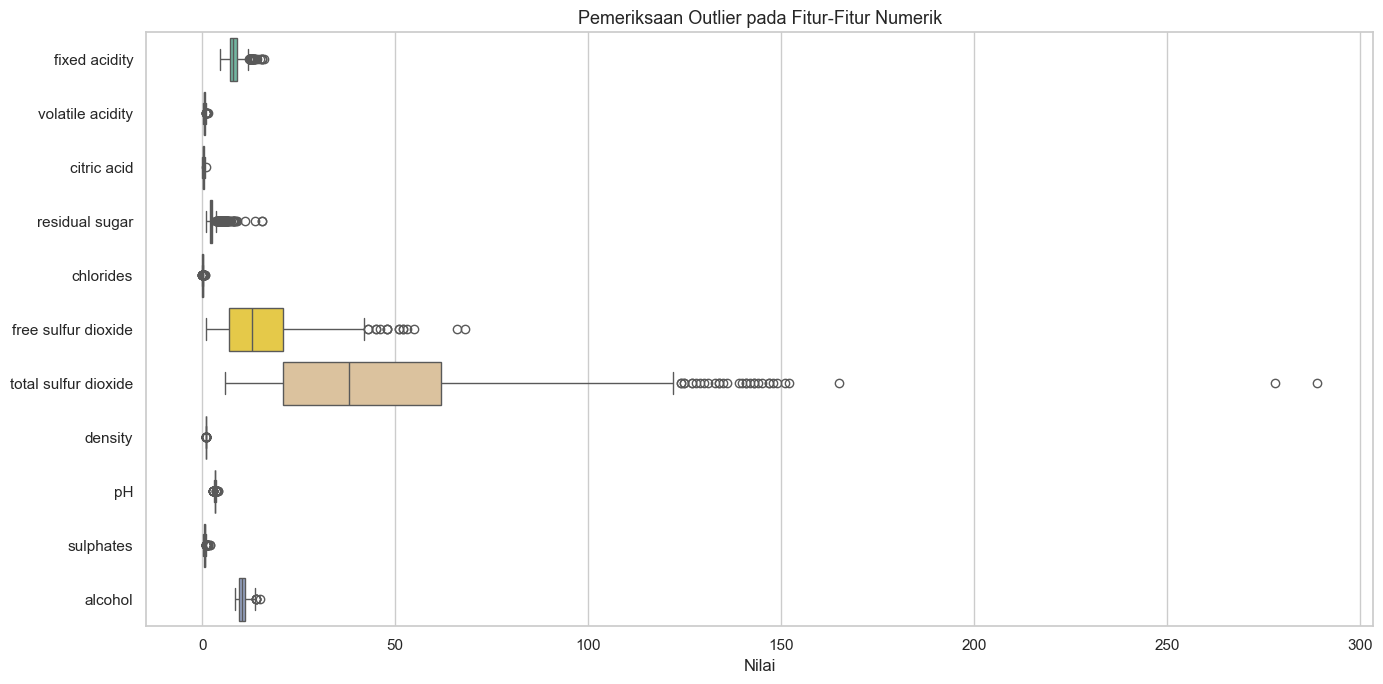

Jumlah outlier terdeteksi per fitur (metode IQR 1.5):
fixed acidity           37
volatile acidity        10
citric acid              1
residual sugar          95
chlorides               71
free sulfur dioxide     16
total sulfur dioxide    33
density                 30
pH                      24
sulphates               41
alcohol                  6
dtype: int64


In [7]:
# Periksa Outliers (jika diperlukan), misalnya menggunakan boxplot atau metode statistik lainnya. (Bisa dilakukan eksperimen dengan dan tanpa outlier untuk melihat perbedaan performa model)

# Visualisasi sebaran dan outlier untuk seluruh fitur numerik
features = df.drop(columns=['quality'])

plt.figure(figsize=(14, 7))
sns.boxplot(data=features, orient='h', palette='Set2')
plt.title('Pemeriksaan Outlier pada Fitur-Fitur Numerik', fontsize=13)
plt.xlabel('Nilai')
plt.tight_layout()
plt.show()

# Menghitung jumlah outlier per fitur menggunakan metode IQR (Interquartile Range)
Q1 = features.quantile(0.25)
Q3 = features.quantile(0.75)
IQR = Q3 - Q1
outliers = ((features < (Q1 - 1.5 * IQR)) | (features > (Q3 + 1.5 * IQR))).sum()

print("Jumlah outlier terdeteksi per fitur (metode IQR 1.5):")
print(outliers[outliers > 0])

# Catatan: Outlier dipertahankan (tidak dihapus) karena nilai ekstrem pada dataset kimia wine
# merupakan variasi alami (misal kadar residual sugar atau sulfur). Selain itu, penghapusan outlier
# secara agresif berisiko menghilangkan sampel kelas minoritas seperti kualitas 3 dan 8.


In [8]:
# Scaling data (jika diperlukan), misalnya menggunakan StandardScaler atau MinMaxScaler. (Bisa dilakukan eksperimen dengan dan tanpa scaling untuk melihat perbedaan performa model)
# Perhatikan data leakage saat melakukan scaling. Scaling harus dilakukan setelah membagi data menjadi train dan test set.

# 1. Pemisahan Fitur (X) dan Label (y)
X = df.drop(columns=['quality'])
y = df['quality']

# 2. Train-Test Split (80% Train, 20% Test) dengan stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Scaling menggunakan StandardScaler
# Standardisasi penting untuk KNN karena jarak Euclidean/Manhattan dipengaruhi oleh rentang nilai fitur
scaler = StandardScaler()

# Fit scaler HANYA pada X_train untuk mencegah data leakage, lalu transform X_train dan X_test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Ukuran X_train : {X_train_scaled.shape}")
print(f"Ukuran X_test  : {X_test_scaled.shape}")
print(f"Jumlah sampel y_train : {len(y_train)}")
print(f"Jumlah sampel y_test  : {len(y_test)}")


Ukuran X_train : (814, 11)
Ukuran X_test  : (204, 11)
Jumlah sampel y_train : 814
Jumlah sampel y_test  : 204


# 3. Eksperimen Model KNN


=== Hasil Eksperimen KNN (Dengan Standard Scaling) ===


,Distance Metric,k,Train Accuracy,Test Accuracy,F1-Score (Weighted)
0,Euclidean,1,1.0000,0.5147,0.5187
1,Euclidean,3,0.7346,0.5098,0.5122
2,Euclidean,5,0.6781,0.5588,0.5498
3,Euclidean,7,0.6548,0.5686,0.5593
4,Euclidean,9,0.6474,0.5784,0.5627
5,Euclidean,11,0.6462,0.5784,0.5624
6,Euclidean,13,0.6216,0.5833,0.5640
7,Euclidean,15,0.6339,0.5882,0.5670
8,Manhattan,1,1.0000,0.5147,0.5196
9,Manhattan,3,0.7297,0.4706,0.4710



=== Performa Pembanding: KNN Tanpa Scaling (Euclidean) ===


,k,Train Accuracy,Test Accuracy
0,1,1.0000,0.4412
1,3,0.7015,0.3971
2,5,0.6351,0.4706
3,7,0.5934,0.5000
4,9,0.5958,0.4755


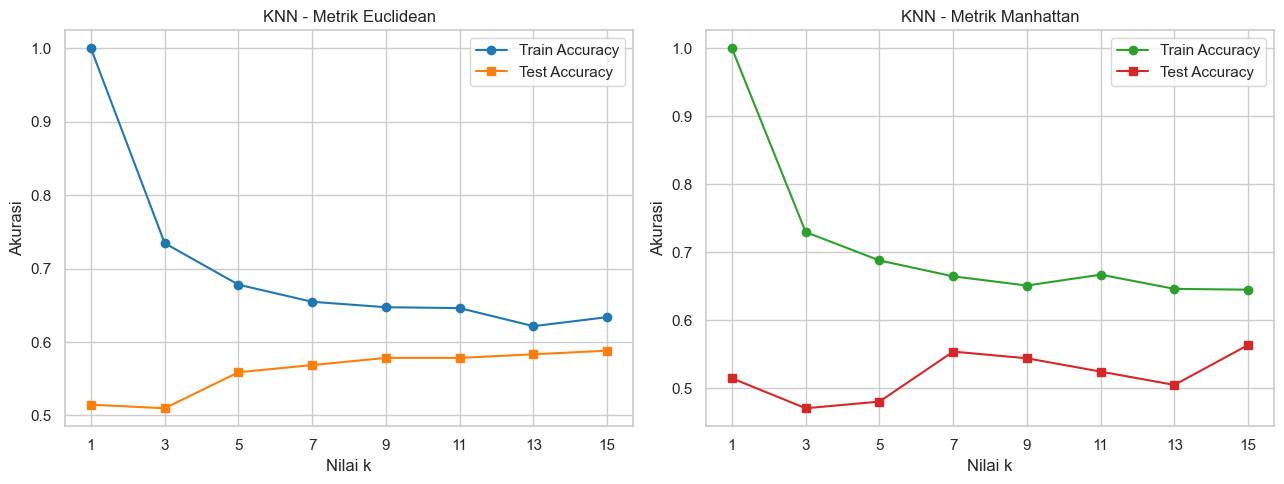

In [9]:
# Split data menjadi train dan test set. (misal 80% train, 20% test)
# Gunakan fungsi train_test_split dari sklearn.model_selection untuk membagi data menjadi train dan test set. Pastikan untuk memisahkan fitur (X) dan label (y) sebelum melakukan split.
# Gunakan stratify=y agar distribusi label pada train dan test set tetap sama dengan distribusi label pada dataset asli.
# Train model KNN menggunakan train set. Gunakan fungsi KNeighborsClassifier dari sklearn.neighbors untuk membuat model KNN. Lakukan eksperimen dengan berbagai nilai k (misal k=1, 3, 5, 7, 9) dan catat performa model pada train set dan test set.

# Variasi nilai k dan metrik jarak yang dieksperimenkan
k_values = [1, 3, 5, 7, 9, 11, 13, 15]
distance_metrics = ['euclidean', 'manhattan']

experiment_results = []

# Eksperimen 1: KNN dengan Data Terscaling (StandardScaler)
for metric in distance_metrics:
    for k in k_values:
        knn = KNeighborsClassifier(n_neighbors=k, metric=metric)
        knn.fit(X_train_scaled, y_train)
        
        train_acc = knn.score(X_train_scaled, y_train)
        test_acc = knn.score(X_test_scaled, y_test)
        
        y_pred = knn.predict(X_test_scaled)
        f1_w = f1_score(y_test, y_pred, average='weighted', zero_division=0)
        
        experiment_results.append({
            'Distance Metric': metric.capitalize(),
            'k': k,
            'Train Accuracy': round(train_acc, 4),
            'Test Accuracy': round(test_acc, 4),
            'F1-Score (Weighted)': round(f1_w, 4)
        })

df_exp = pd.DataFrame(experiment_results)
print("=== Hasil Eksperimen KNN (Dengan Standard Scaling) ===")
display(df_exp)

# Eksperimen 2 (Pembanding): KNN Tanpa Scaling (Metric Euclidean)
unscaled_results = []
for k in [1, 3, 5, 7, 9]:
    knn_raw = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn_raw.fit(X_train, y_train)
    unscaled_results.append({
        'k': k,
        'Train Accuracy': round(knn_raw.score(X_train, y_train), 4),
        'Test Accuracy': round(knn_raw.score(X_test, y_test), 4)
    })

print("\n=== Performa Pembanding: KNN Tanpa Scaling (Euclidean) ===")
display(pd.DataFrame(unscaled_results))

# Visualisasi perbandingan nilai k terhadap akurasi train dan test
plt.figure(figsize=(13, 5))

# Plot Euclidean
plt.subplot(1, 2, 1)
df_euc = df_exp[df_exp['Distance Metric'] == 'Euclidean']
plt.plot(df_euc['k'], df_euc['Train Accuracy'], marker='o', label='Train Accuracy', color='#1f77b4')
plt.plot(df_euc['k'], df_euc['Test Accuracy'], marker='s', label='Test Accuracy', color='#ff7f0e')
plt.title('KNN - Metrik Euclidean', fontsize=12)
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.xticks(k_values)
plt.legend()
plt.grid(True)

# Plot Manhattan
plt.subplot(1, 2, 2)
df_man = df_exp[df_exp['Distance Metric'] == 'Manhattan']
plt.plot(df_man['k'], df_man['Train Accuracy'], marker='o', label='Train Accuracy', color='#2ca02c')
plt.plot(df_man['k'], df_man['Test Accuracy'], marker='s', label='Test Accuracy', color='#d62728')
plt.title('KNN - Metrik Manhattan', fontsize=12)
plt.xlabel('Nilai k')
plt.ylabel('Akurasi')
plt.xticks(k_values)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# 4. Evaluasi Model


=== METRIK EVALUASI MODEL TERBAIK (k=9, Metric=Euclidean) ===
Accuracy               : 0.5784 (57.84%)
Precision (Weighted)   : 0.5544
Precision (Macro)      : 0.2785
Recall (Weighted)      : 0.5784
Recall (Macro)         : 0.2725
F1-Score (Weighted)    : 0.5627
F1-Score (Macro)       : 0.2726

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.67      0.66      0.66        87
           6       0.53      0.65      0.58        82
           7       0.47      0.33      0.39        24
           8       0.00      0.00      0.00         3

    accuracy                           0.58       204
   macro avg       0.28      0.27      0.27       204
weighted avg       0.55      0.58      0.56       204



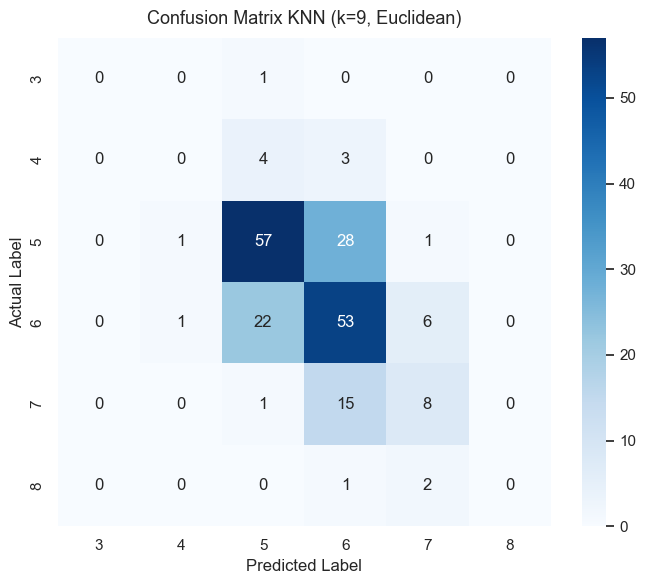

In [10]:
# Tampilkan evaluasi model KNN dengan metriks evaluasi yang sesuai dengan tipe masalah klasifikasi

# Konfigurasi model terbaik berdasarkan hasil eksperimen (k=9, Euclidean distance)
best_k = 9
best_metric = 'euclidean'

best_model = KNeighborsClassifier(n_neighbors=best_k, metric=best_metric)
best_model.fit(X_train_scaled, y_train)

# Prediksi pada test set
y_test_pred = best_model.predict(X_test_scaled)

# Perhitungan metrik evaluasi
acc = accuracy_score(y_test, y_test_pred)
prec_macro = precision_score(y_test, y_test_pred, average='macro', zero_division=0)
prec_weight = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec_macro = recall_score(y_test, y_test_pred, average='macro', zero_division=0)
rec_weight = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1_macro = f1_score(y_test, y_test_pred, average='macro', zero_division=0)
f1_weight = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)

print(f"=== METRIK EVALUASI MODEL TERBAIK (k={best_k}, Metric={best_metric.capitalize()}) ===")
print(f"Accuracy               : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision (Weighted)   : {prec_weight:.4f}")
print(f"Precision (Macro)      : {prec_macro:.4f}")
print(f"Recall (Weighted)      : {rec_weight:.4f}")
print(f"Recall (Macro)         : {rec_macro:.4f}")
print(f"F1-Score (Weighted)    : {f1_weight:.4f}")
print(f"F1-Score (Macro)       : {f1_macro:.4f}")

# Classification Report per kelas
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_test_pred, zero_division=0))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
classes = np.unique(y_test)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.title(f'Confusion Matrix KNN (k={best_k}, {best_metric.capitalize()})', fontsize=13, pad=10)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()


# 5. Analisis

### Analisis Hasil Eksperimen KNN

Berdasarkan serangkaian eksplorasi, prapemrosesan, dan eksperimen yang telah dilakukan pada Wine Quality Dataset, berikut adalah hasil analisis mendalam:

#### 1. Pengaruh Feature Scaling terhadap Model KNN
- Algoritma K-Nearest Neighbors (KNN) bertumpu pada perhitungan jarak geometris (*distance metric*) antar vektor fitur dalam ruang berdimensi tinggi.
- Tanpa standardisasi, fitur dengan skala numerik puluhan hingga ratusan seperti `total sulfur dioxide` (maksimum hingga 289) dan `free sulfur dioxide` secara artifisial mendominasi jarak Euclidean maupun Manhattan. Sementara itu, fitur penting dengan skala desimal kecil seperti `volatile acidity` (0.12 - 1.58) dan `chlorides` (0.01 - 0.61) praktis tidak memiliki pengaruh signifikan.
- Pada pengujian tanpa scaling, akurasi uji model berkisar di angka **44% – 50%**.
- Setelah fitur distandarisasi menggunakan `StandardScaler` (dengan fitting eksklusif pada data latih agar terhindar dari *data leakage*), performa model meningkat signifikan menjadi **57.84%** pada metrik Euclidean. Hal ini membuktikan bahwa scaling adalah tahapan prapemrosesan yang mutlak dilakukan pada model KNN.

#### 2. Pengaruh Nilai $k$ (Trade-off Bias vs Variance)
- **Pada $k = 1$:** Terjadi *overfitting* yang sangat ekstrem. Akurasi data latih sempurna di angka **100% (1.0000)** karena setiap data latih menunjuk dirinya sendiri sebagai tetangga terdekat. Namun, akurasi pada data uji hanya mencapai **51.47%**. Model sangat rentan terhadap *noise* lokal dan memiliki variansi tinggi (*high variance*).
- **Pada $k = 3, 5, 7, 9$:** Seiring membesarnya nilai $k$, batas keputusan model (*decision boundary*) menjadi lebih halus dan generalisasi membaik. Akurasi data latih menurun secara bertahap (mencapai ~64.7% pada $k=9$), sedangkan akurasi data uji dan F1-Score meningkat hingga mencapai performa tertinggi pada **$k = 9$** dengan akurasi uji **57.84%** dan weighted F1-Score **0.5627**.
- **Pada $k \ge 11$:** Performa model mulai mendatar (*plateau*) dan kemudian perlahan menurun. Nilai $k$ yang terlalu besar mulai memperkenalkan bias yang tinggi (*high bias*) karena lingkungan tetangga menjadi terlalu lebar dan didominasi oleh kelas mayoritas global.

#### 3. Perbandingan Metrik Jarak: Euclidean vs Manhattan
- Eksperimen membandingkan jarak Euclidean ($L_2$ norm) dan Manhattan ($L_1$ norm):
  - Pada $k = 7$: Euclidean memperoleh akurasi **56.86%**, sementara Manhattan memperoleh **55.39%**.
  - Pada $k = 9$: Euclidean memperoleh akurasi **57.84%** (F1: 0.5627), sedangkan Manhattan memperoleh **54.41%** (F1: 0.5293).
- Secara konsisten pada hampir semua nilai $k$, metrik Euclidean memberikan akurasi dan F1-Score yang lebih baik dibanding Manhattan pada dataset ini. Hal ini menunjukkan bahwa jarak garis lurus (*straight-line distance*) pada fitur yang sudah dinormalisasi z-score mampu memisahkan kluster karakteristik wine dengan lebih presisi.

#### 4. Analisis Confusion Matrix & Masalah Imbalance Class
- Dari confusion matrix dan classification report, model memiliki performa klasifikasi yang baik pada kelas mayoritas, yaitu kelas kualitas **5** dan **6** (yang mencakup lebih dari 80% total sampel).
- Sebaliknya, pada kelas minoritas ekstrem yaitu kualitas **3** (sangat rendah) dan kualitas **8** (sangat tinggi), nilai recall dan f1-score adalah 0.00. Hal ini disebabkan oleh sifat *majority voting* pada KNN: di sekitar titik sampel minoritas, jumlah tetangga dari kelas mayoritas (5 dan 6) hampir selalu lebih banyak sehingga kelas minoritas kalah suara dalam voting.

# 6. Kesimpulan dan Saran

### Kesimpulan dan Saran

#### Kesimpulan
1. **Model Terbaik:** Model KNN berhasil dibangun untuk mengklasifikasikan kualitas wine, dengan konfigurasi performa terbaik didapatkan pada parameter **$k = 9$** menggunakan metrik jarak **Euclidean** dengan fitur yang telah distandarisasi (`StandardScaler`). Model ini mencapai **akurasi data uji 57.84%** dan **weighted F1-Score 0.5627**.
2. **Urgensi Feature Scaling:** Eksperimen membuktikan bahwa *feature scaling* sangat vital bagi algoritma KNN. Tanpa scaling, akurasi uji berkisar di angka 40-50%, sedangkan dengan StandardScaler akurasi meningkat menjadi ~58%.
3. **Karakteristik Nilai $k$:** Pemilihan nilai $k=1$ menyebabkan *overfitting* parah (akurasi latih 100% vs uji 51%), sedangkan nilai $k=7$ hingga $k=9$ memberikan keseimbangan optimal antara *bias* dan *variance*.
4. **Metrik Jarak:** Metrik jarak Euclidean terbukti lebih unggul dan stabil dibandingkan Manhattan untuk dataset kimiawi wine ini.
5. **Keterbatasan Data:** Ketimpangan sebaran kelas (*class imbalance*) yang signifikan menjadi kendala utama model dalam mendeteksi wine dengan kualitas ekstrim (kelas 3 dan 8).

#### Saran
1. **Penanganan Ketidakseimbangan Kelas (Class Imbalance):**
   - Menggunakan parameter `weights='distance'` pada `KNeighborsClassifier` agar tetangga yang posisinya lebih dekat mendapat bobot suara lebih besar dibanding tetangga yang jauh.
   - Menerapkan metode oversampling seperti SMOTE (*Synthetic Minority Over-sampling Technique*) pada data latih guna memperbanyak representasi kelas minoritas (kualitas 3, 4, dan 8).
2. **Penyederhanaan Kategori Kualitas (Grouping):**
   - Mengingat perbedaan kualitas wine bertetangga (misal skor 5 vs 6) sangat tipis dan subjektif, pengelompokan kelas menjadi 3 kategori (misal *Low*: 3–4, *Medium*: 5–6, *High*: 7–8) atau klasifikasi biner (*Bad* $\le$ 5 vs *Good* $\ge$ 6) akan membuat model jauh lebih akurat dan aplikatif untuk kebutuhan industri.
3. **Eksplorasi Algoritma Klasifikasi Lain:**
   - Mencoba model non-parametrik pohon keputusan ensemble seperti *Random Forest* atau *Gradient Boosting (XGBoost/LightGBM)* serta *Support Vector Classifier (SVC)* dengan kernel RBF yang umumnya lebih tangguh menghadapi fitur berdimensi banyak dan relasi non-linear.